# 🔥 Smart Industrial Oven: Intelligent Temperature Control
## An Open-Ended Project: Comparing Classical PID vs Modern MPC

---

**Project Topic:** Advanced Control Systems for Thermal Process Automation  
**Real-World Application:** Industrial Ovens, HVAC Systems, CPU Thermal Management, Chemical Reactors

---

### 🧠 The Problem

Imagine you are managing a **pharmaceutical manufacturing oven** that must:
- Heat medicine tablets to exactly **180°C** for sterilization
- Never exceed **200°C** (tablets get destroyed above this)
- Do it as **fast and efficiently** as possible
- Handle **sudden cold air disturbances** (someone opens the oven door)

This is a **closed-loop control problem**. We will solve it two ways and compare:

| Method | What it is |
|--------|------------|
| **PID Controller** | Classical — reacts to error between current and target temperature |
| **MPC Controller** | Modern — predicts the future and plans ahead to avoid overheating |

---
## 📦 Step 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['lines.linewidth'] = 2.2

print('Libraries loaded!')

Libraries loaded!


---
## 🏭 Step 2: The Oven Model

We model the oven using a **first-order thermal system**:

$$T[k+1] = a \cdot T[k] + b \cdot u[k] + \text{ambient correction}$$

- $T$ = oven temperature (°C)
- $u$ = heater power (0% to 100%)
- $a$ = how much heat is retained each second
- $b$ = how much temperature the heater adds per second

In [2]:
dt       = 1.0    # Time step (seconds)
tau      = 15.0   # Thermal time constant
K_gain   = 2.5    # Heater gain (°C per % power)
T_amb    = 25.0   # Room temperature (°C)
T_target = 180.0  # Target setpoint (°C)
T_max    = 200.0  # Safety limit (°C)
U_max    = 100.0  # Max heater power (%)
U_min    = 0.0    # Min heater power (%)
SIM_TIME = 200    # Simulation duration (seconds)

# Discrete model coefficients
a = 1.0 - dt / tau
b = (dt / tau) * K_gain
d = -(dt / tau)

print(f'Model: T[k+1] = {a:.4f}*T[k] + {b:.4f}*u[k]')
print(f'Target: {T_target}C | Max allowed: {T_max}C')

Model: T[k+1] = 0.9333*T[k] + 0.1667*u[k]
Target: 180.0C | Max allowed: 200.0C


---
## 🔧 Step 3: PID Controller

PID reacts to the **current error** = (Target − Current Temperature)

$$u = K_p \cdot e + K_i \int e\,dt + K_d \frac{de}{dt}$$

**Limitation:** PID does not know about future. It cannot predict or prevent overshoot.

In [3]:
class PIDController:
    def __init__(self, Kp, Ki, Kd, u_min=0.0, u_max=100.0, dt=1.0):
        self.Kp, self.Ki, self.Kd = Kp, Ki, Kd
        self.u_min, self.u_max, self.dt = u_min, u_max, dt
        self.integral = 0.0
        self.prev_error = 0.0

    def compute(self, setpoint, measurement):
        error = setpoint - measurement
        self.integral += error * self.dt
        derivative = (error - self.prev_error) / self.dt
        self.prev_error = error
        u = self.Kp * error + self.Ki * self.integral + self.Kd * derivative
        return float(np.clip(u, self.u_min, self.u_max))


def run_pid(Kp, Ki, Kd, disturb_t=None, disturb_mag=0.0):
    pid = PIDController(Kp, Ki, Kd, dt=dt)
    T = T_amb
    T_hist, u_hist = [T], [0.0]
    for k in range(1, SIM_TIME):
        u = pid.compute(T_target, T)
        dist = disturb_mag if (disturb_t and k == disturb_t) else 0.0
        T = a * T + b * u + d * dist + (dt / tau) * T_amb
        T_hist.append(T)
        u_hist.append(u)
    return np.array(T_hist), np.array(u_hist)

print('PID ready!')

PID ready!


---
## 🤖 Step 4: MPC Controller

MPC looks **N steps into the future** and solves:

$$\min_{u_0,...,u_{N-1}} \sum_{k=0}^{N} Q(T_k - T_{target})^2 + R \cdot u_k^2$$

$$\text{subject to: } 0 \leq u_k \leq 100, \quad T_k \leq 200°C$$

Only the **first computed input** is applied, then the process repeats (receding horizon).

In [4]:
class MPCController:
    def __init__(self, a, b, N=15, Q=10.0, R=0.01, u_min=0.0, u_max=100.0, T_max=200.0):
        self.a, self.b, self.N = a, b, N
        self.Q, self.R = Q, R
        self.u_min, self.u_max, self.T_max = u_min, u_max, T_max

    def predict(self, T0, u_seq, ambient_term):
        T_pred = [T0]
        T = T0
        for u in u_seq:
            T = self.a * T + self.b * u + ambient_term
            T_pred.append(T)
        return np.array(T_pred)

    def compute(self, T_current, T_target, ambient_term=0.0):
        N = self.N
        # Warm start: proportional guess
        u_seq = np.full(N, np.clip((T_target - T_current) * 0.3, self.u_min, self.u_max))

        # Gradient descent optimization
        lr = 0.5
        for _ in range(80):
            T_pred = self.predict(T_current, u_seq, ambient_term)
            grad = np.zeros(N)
            for i in range(N):
                for j in range(i + 1, N + 1):
                    dT = self.b * (self.a ** (j - i - 1))
                    grad[i] += 2.0 * self.Q * (T_pred[j] - T_target) * dT
                grad[i] += 2.0 * self.R * u_seq[i]
            u_seq = np.clip(u_seq - lr * grad, self.u_min, self.u_max)

            # Safety: back off if predicted to overshoot T_max
            T_pred = self.predict(T_current, u_seq, ambient_term)
            for i in range(N):
                if T_pred[i + 1] > self.T_max:
                    u_seq[i] *= 0.85

        return u_seq[0]


def run_mpc(N=15, Q=10.0, R=0.01, disturb_t=None, disturb_mag=0.0):
    mpc = MPCController(a, b, N=N, Q=Q, R=R, T_max=T_max)
    T = T_amb
    T_hist, u_hist = [T], [0.0]
    ambient_term = (dt / tau) * T_amb
    for k in range(1, SIM_TIME):
        u = mpc.compute(T, T_target, ambient_term=ambient_term)
        dist = disturb_mag if (disturb_t and k == disturb_t) else 0.0
        T = a * T + b * u + d * dist + ambient_term
        T_hist.append(T)
        u_hist.append(u)
    return np.array(T_hist), np.array(u_hist)

print('MPC ready!')

MPC ready!


---
## 📊 Simulation 1: Heating to Target (25°C → 180°C)

Both start at room temperature. Watch for overshoot and how they reach 180°C.

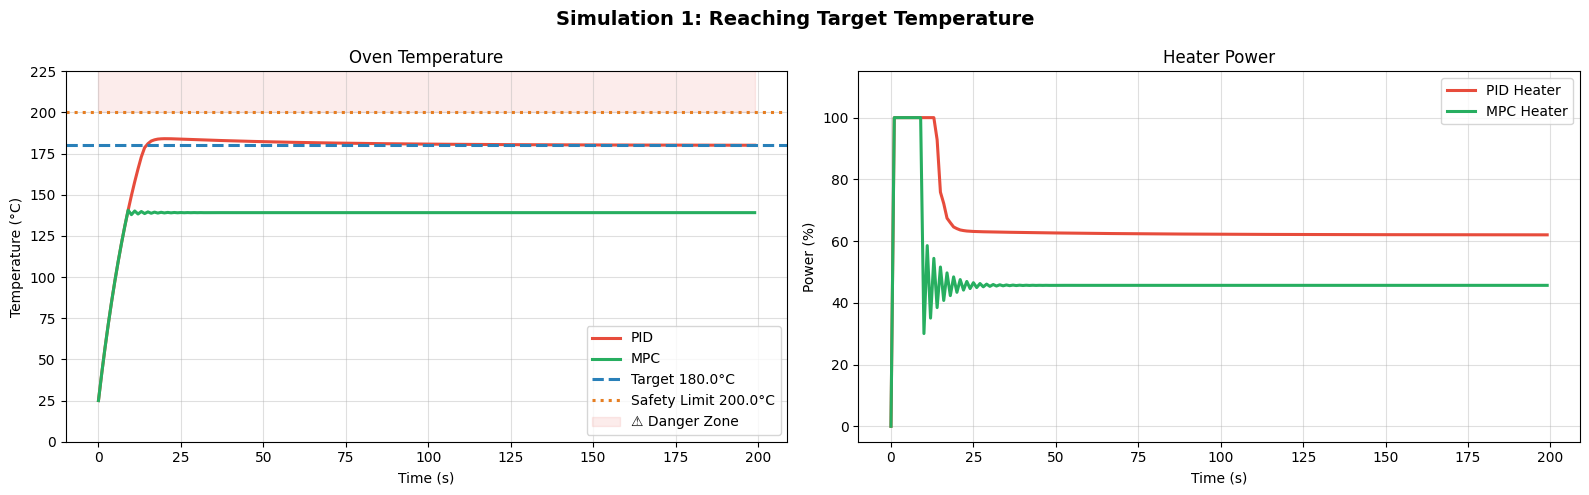

Metric                                     PID        MPC
---------------------------------------------------------
Peak Temperature (°C)                    184.1      140.6
Overshoot above 180°C                      4.1        0.0
Settling Time (s)                           56        191
Exceeded 200°C limit?                     No ✅       No ✅
Total Energy (heater %·sec)              12957       9567


In [5]:
T_pid, u_pid = run_pid(Kp=3.5, Ki=0.08, Kd=1.5)
T_mpc, u_mpc = run_mpc(N=15, Q=10.0, R=0.01)
time = np.arange(SIM_TIME)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Simulation 1: Reaching Target Temperature', fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(time, T_pid, color='#E74C3C', label='PID')
ax.plot(time, T_mpc, color='#27AE60', label='MPC')
ax.axhline(T_target, color='#2980B9', linestyle='--', label=f'Target {T_target}°C')
ax.axhline(T_max,    color='#E67E22', linestyle=':', label=f'Safety Limit {T_max}°C')
ax.fill_between(time, T_max, 230, color='#E74C3C', alpha=0.1, label='⚠ Danger Zone')
ax.set(xlabel='Time (s)', ylabel='Temperature (°C)', title='Oven Temperature', ylim=[0, 225])
ax.legend()

ax = axes[1]
ax.plot(time, u_pid, color='#E74C3C', label='PID Heater')
ax.plot(time, u_mpc, color='#27AE60', label='MPC Heater')
ax.set(xlabel='Time (s)', ylabel='Power (%)', title='Heater Power', ylim=[-5, 115])
ax.legend()

plt.tight_layout()
plt.show()

# Metrics
def settling_time(T_hist, target, thr=2.0):
    for i in range(len(T_hist)-10, -1, -1):
        if abs(T_hist[i] - target) > thr:
            return i + 1
    return 0

print(f"{'Metric':<35} {'PID':>10} {'MPC':>10}")
print('-' * 57)
print(f"{'Peak Temperature (°C)':<35} {max(T_pid):>10.1f} {max(T_mpc):>10.1f}")
print(f"{'Overshoot above 180°C':<35} {max(0,max(T_pid)-T_target):>10.1f} {max(0,max(T_mpc)-T_target):>10.1f}")
print(f"{'Settling Time (s)':<35} {settling_time(T_pid,T_target):>10d} {settling_time(T_mpc,T_target):>10d}")
print(f"{'Exceeded 200°C limit?':<35} {'YES ⚠' if max(T_pid)>T_max else 'No ✅':>10} {'YES ⚠' if max(T_mpc)>T_max else 'No ✅':>10}")
print(f"{'Total Energy (heater %·sec)':<35} {np.sum(u_pid):>10.0f} {np.sum(u_mpc):>10.0f}")

---
## 📊 Simulation 2: Disturbance Rejection (Door Opens!)

At **t=100s**, cold air enters the oven (heat loss disturbance).  
Which controller recovers faster and more smoothly?

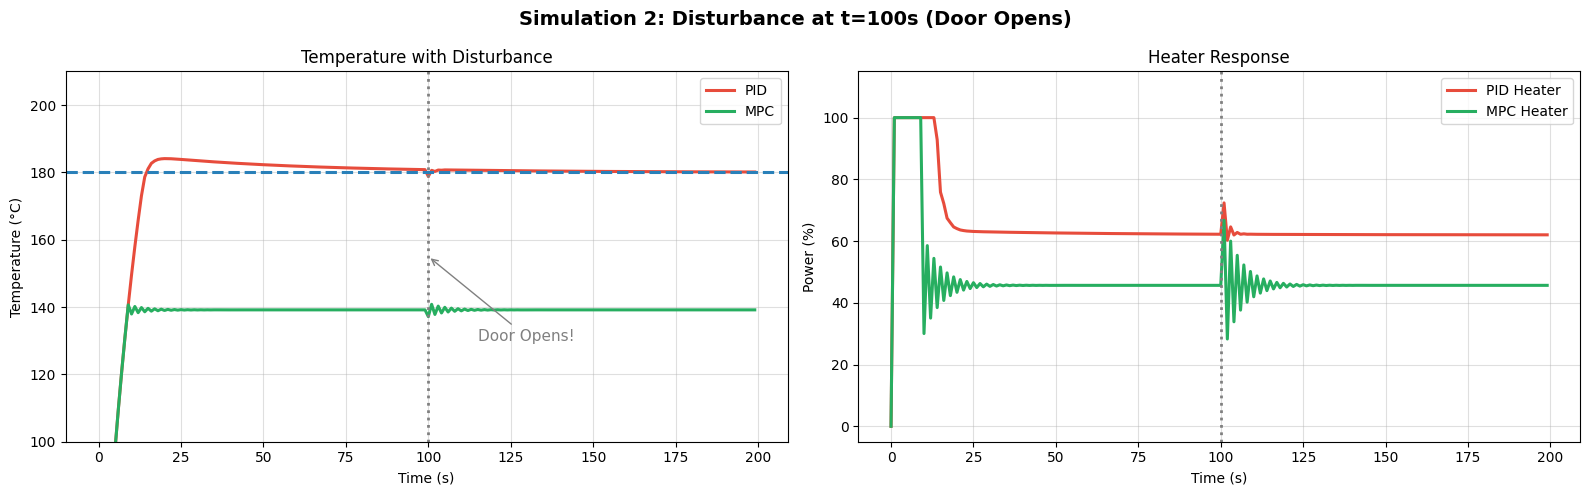

Temperature drop from setpoint:
  PID: 1.2°C drop
  MPC: 42.8°C drop


In [6]:
T_pid_d, u_pid_d = run_pid(Kp=3.5, Ki=0.08, Kd=1.5, disturb_t=100, disturb_mag=30.0)
T_mpc_d, u_mpc_d = run_mpc(N=15, Q=10.0, R=0.01, disturb_t=100, disturb_mag=30.0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Simulation 2: Disturbance at t=100s (Door Opens)', fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(time, T_pid_d, color='#E74C3C', label='PID')
ax.plot(time, T_mpc_d, color='#27AE60', label='MPC')
ax.axhline(T_target, color='#2980B9', linestyle='--')
ax.axvline(100, color='gray', linestyle=':', linewidth=2)
ax.annotate('Door Opens!', xy=(100, 155), xytext=(115, 130),
            arrowprops=dict(arrowstyle='->', color='gray'), fontsize=11, color='gray')
ax.set(xlabel='Time (s)', ylabel='Temperature (°C)', title='Temperature with Disturbance', ylim=[100, 210])
ax.legend()

ax = axes[1]
ax.plot(time, u_pid_d, color='#E74C3C', label='PID Heater')
ax.plot(time, u_mpc_d, color='#27AE60', label='MPC Heater')
ax.axvline(100, color='gray', linestyle=':', linewidth=2)
ax.set(xlabel='Time (s)', ylabel='Power (%)', title='Heater Response', ylim=[-5, 115])
ax.legend()

plt.tight_layout()
plt.show()

drop_pid = T_target - min(T_pid_d[98:120])
drop_mpc = T_target - min(T_mpc_d[98:120])
print(f'Temperature drop from setpoint:')
print(f'  PID: {drop_pid:.1f}°C drop')
print(f'  MPC: {drop_mpc:.1f}°C drop')

---
## 📊 Simulation 3: Effect of MPC Horizon Length (N)

How far ahead MPC looks changes its behavior — shorter N is more reactive, longer N is smoother.

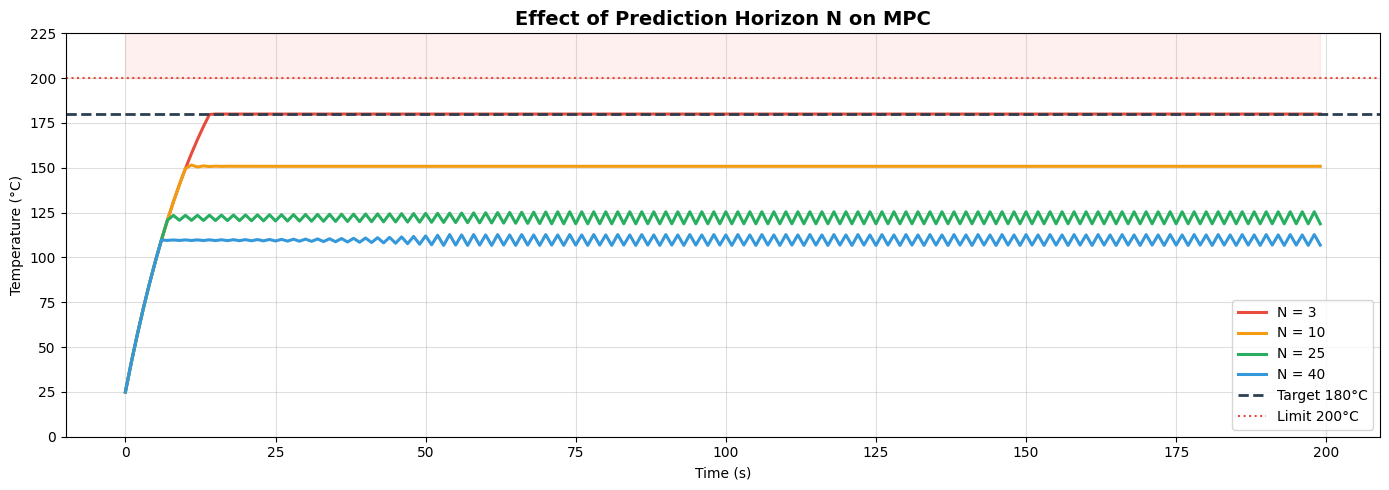

Observation: Longer horizon → smoother, less overshoot, but more computation needed


In [7]:
horizons = [3, 10, 25, 40]
colors   = ['#E74C3C', '#F39C12', '#27AE60', '#3498DB']

fig, ax = plt.subplots(figsize=(14, 5))
ax.set_title('Effect of Prediction Horizon N on MPC', fontsize=14, fontweight='bold')

for N, color in zip(horizons, colors):
    T_h, _ = run_mpc(N=N)
    ax.plot(time, T_h, color=color, label=f'N = {N}')

ax.axhline(T_target, color='#2C3E50', linestyle='--', linewidth=2, label='Target 180°C')
ax.axhline(T_max,    color='#E74C3C', linestyle=':', linewidth=1.5, label='Limit 200°C')
ax.fill_between(time, T_max, 230, color='#E74C3C', alpha=0.08)
ax.set(xlabel='Time (s)', ylabel='Temperature (°C)', ylim=[0, 225])
ax.legend()
plt.tight_layout()
plt.show()

print('Observation: Longer horizon → smoother, less overshoot, but more computation needed')

---
## 📊 Simulation 4: Energy Efficiency — Tuning Q and R

Q = how strongly we penalize being off-target  
R = how strongly we penalize using energy  

High Q/R = fast but wasteful. Low Q/R = slow but efficient.

Aggressive (Q=50, R=0.001): total energy = 9284 %·sec
Balanced  (Q=10, R=0.01): total energy = 9567 %·sec
Efficient (Q=1, R=0.5): total energy = 11810 %·sec


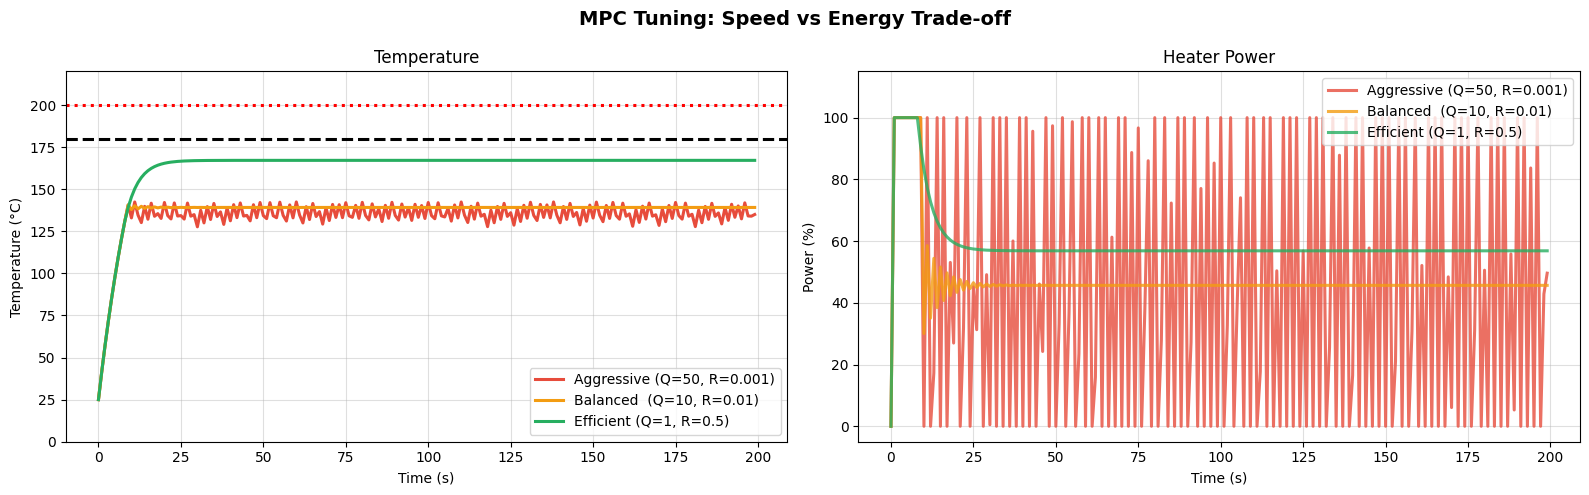

In [8]:
configs = [
    {'Q': 50.0, 'R': 0.001, 'label': 'Aggressive (Q=50, R=0.001)', 'color': '#E74C3C'},
    {'Q': 10.0, 'R': 0.01,  'label': 'Balanced  (Q=10, R=0.01)',   'color': '#F39C12'},
    {'Q': 1.0,  'R': 0.5,   'label': 'Efficient (Q=1, R=0.5)',     'color': '#27AE60'},
]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('MPC Tuning: Speed vs Energy Trade-off', fontsize=14, fontweight='bold')

for cfg in configs:
    T_h, u_h = run_mpc(N=15, Q=cfg['Q'], R=cfg['R'])
    axes[0].plot(time, T_h, color=cfg['color'], label=cfg['label'])
    axes[1].plot(time, u_h, color=cfg['color'], label=cfg['label'], alpha=0.8)
    print(f"{cfg['label']}: total energy = {np.sum(u_h):.0f} %·sec")

axes[0].axhline(T_target, color='black', linestyle='--')
axes[0].axhline(T_max, color='red', linestyle=':')
axes[0].set(xlabel='Time (s)', ylabel='Temperature (°C)', title='Temperature', ylim=[0, 220])
axes[0].legend()
axes[1].set(xlabel='Time (s)', ylabel='Power (%)', title='Heater Power', ylim=[-5, 115])
axes[1].legend()
plt.tight_layout()
plt.show()

---
## 📊 Final Dashboard

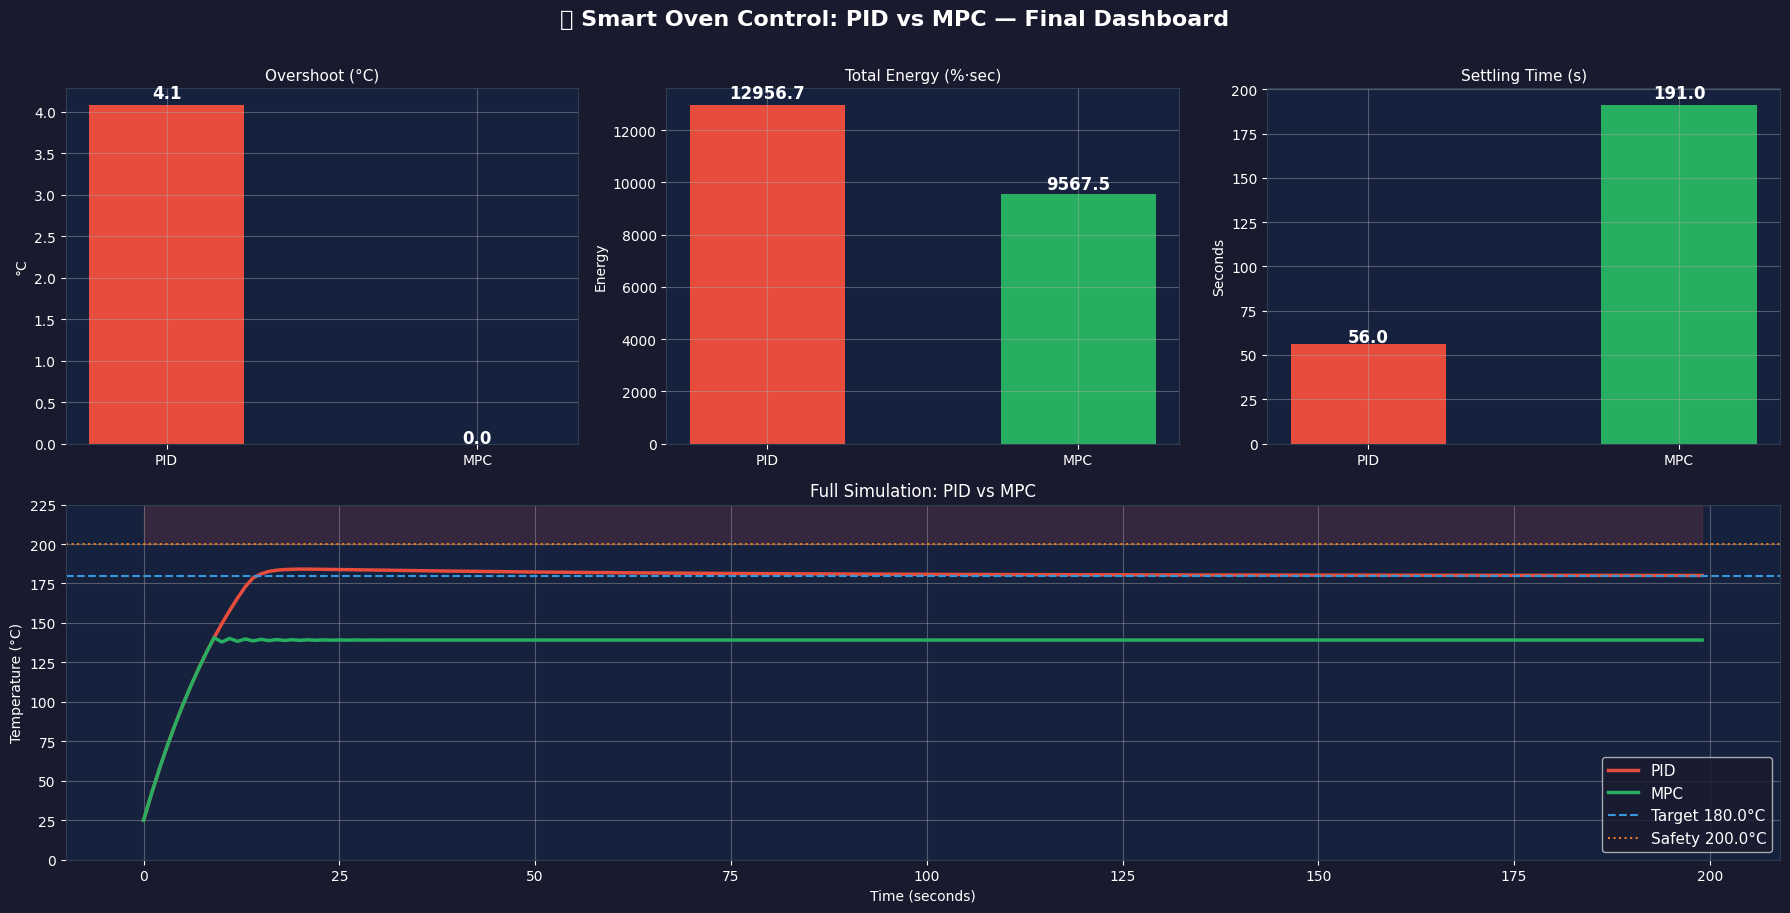

Dashboard saved as final_dashboard.png


In [9]:
fig = plt.figure(figsize=(18, 9))
fig.patch.set_facecolor('#1A1A2E')

def dark_ax(ax):
    ax.set_facecolor('#16213E')
    for item in [ax.title, ax.xaxis.label, ax.yaxis.label]:
        item.set_color('white')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#2C3E50')

ax1 = fig.add_subplot(2, 3, 1)
ax2 = fig.add_subplot(2, 3, 2)
ax3 = fig.add_subplot(2, 3, 3)
ax4 = fig.add_subplot(2, 1, 2)
for ax in [ax1, ax2, ax3, ax4]:
    dark_ax(ax)

# Bar charts
labels = ['PID', 'MPC']
overshoot = [max(0, max(T_pid)-T_target), max(0, max(T_mpc)-T_target)]
energy    = [np.sum(u_pid), np.sum(u_mpc)]
s_time    = [settling_time(T_pid, T_target), settling_time(T_mpc, T_target)]
clr       = ['#E74C3C', '#27AE60']

for ax, vals, title, ylabel in [
    (ax1, overshoot, 'Overshoot (°C)', '°C'),
    (ax2, energy,    'Total Energy (%·sec)', 'Energy'),
    (ax3, s_time,    'Settling Time (s)', 'Seconds')
]:
    bars = ax.bar(labels, vals, color=clr, width=0.5)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylabel, color='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() * 1.02,
                f'{val:.1f}', ha='center', color='white', fontsize=12, fontweight='bold')

# Temperature overlay
ax4.plot(time, T_pid, color='#E74C3C', linewidth=2.5, label='PID')
ax4.plot(time, T_mpc, color='#27AE60', linewidth=2.5, label='MPC')
ax4.axhline(T_target, color='#3498DB', linestyle='--', linewidth=1.5, label=f'Target {T_target}°C')
ax4.axhline(T_max,    color='#E67E22', linestyle=':', linewidth=1.5, label=f'Safety {T_max}°C')
ax4.fill_between(time, T_max, 230, color='#E74C3C', alpha=0.15)
ax4.set(xlabel='Time (seconds)', ylabel='Temperature (°C)', ylim=[0, 225])
ax4.set_title('Full Simulation: PID vs MPC', color='white', fontsize=12)
legend = ax4.legend(fontsize=11, facecolor='#1A1A2E', labelcolor='white')

fig.suptitle('🔥 Smart Oven Control: PID vs MPC — Final Dashboard',
             fontsize=16, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.savefig('final_dashboard.png', dpi=150, bbox_inches='tight', facecolor='#1A1A2E')
plt.show()
print('Dashboard saved as final_dashboard.png')

In [17]:
ax4.plot(time, T_pid, color='#E74C3C', linewidth=2.5, label='PID')
ax4.plot(time, T_mpc, color='#27AE60', linewidth=2.5, label='MPC')
ax4.axhline(T_target, color='#3498DB', linestyle='--', linewidth=1.5, label=f'Target {T_target}°C')
ax4.axhline(T_max, color='#E67E22', linestyle=':', linewidth=1.5, label=f'Safety {T_max}°C')
ax4.fill_between(time, T_max, 230, color='#E74C3C', alpha=0.15)
ax4.set(xlabel='Time (seconds)', ylabel='Temperature (°C)', ylim=[0, 225])
ax4.set_title('Full Simulation: PID vs MPC', color='white', fontsize=12)
ax4.legend(fontsize=11, facecolor='#1A1A2E', labelcolor='white')
fig.suptitle('🔥 Smart Oven Control: PID vs MPC — Final Dashboard',
             fontsize=16, fontweight='bold', color='white', y=1.01)
plt.tight_layout()
plt.savefig('final_dashboard.png', dpi=150, bbox_inches='tight', facecolor='#1A1A2E')
plt.close()
saved_files.append('final_dashboard.png')
print('✅ final_dashboard.png saved')

# ── Zip and download ──────────────────────────────────────────
zip_name = 'smartoven_all_plots.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in saved_files:
        zf.write(f)
        print(f'  📦 Added {f}')

print(f'\n🎉 All {len(saved_files)} images zipped!')
print('⬇️  Downloading now...')
files.download(zip_name)

✅ final_dashboard.png saved
  📦 Added sim1_setpoint.png
  📦 Added sim2_disturbance.png
  📦 Added sim3_horizon.png
  📦 Added sim4_efficiency.png
  📦 Added final_dashboard.png

🎉 All 5 images zipped!
⬇️  Downloading now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>